## #21 Parameter Initialization

In [1]:
import tensorflow as tf
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import os
import numpy as np
import matplotlib.pyplot as plt

In [4]:
data_dir = r"D:/Learning/AI_MachineLearning/DeepLearning/Aghamohammadi/Original_Course\DLAghmohamadiCodes\caltech-101"\
            r"\caltech-101\101_ObjectCategories.tar\101_ObjectCategories"

def load_dataset_from_dir(data_dir, img_height=224, img_width=224, batch_size=32):
    # Load the entire dataset (train+val) without split
    ds = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        labels="inferred",
        label_mode="int",
        image_size=(img_height, img_width),
        batch_size=None,
        shuffle=True,
    )
    return ds

def shuffle_dataset(ds):
    buffer_size = tf.data.experimental.cardinality(ds).numpy()
    return ds.shuffle(buffer_size)

def split_dataset(ds, train_ratio=0.9):
    num_examples = tf.data.experimental.cardinality(ds).numpy()
    num_train = int(train_ratio * num_examples)
    train_ds = ds.take(num_train)
    test_ds = ds.skip(num_train)
    return train_ds, test_ds

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1
    image = tf.image.resize(image, (224, 224))
    return image, label

def prepare_dataset(ds, batch_size=32):
    return ds.map(preprocess).batch(batch_size)

# Load the raw dataset from the folder
all_ds = load_dataset_from_dir(data_dir)
# Shuffle the entire dataset
all_ds = shuffle_dataset(all_ds)
# Split into train and test
train_ds, test_ds = split_dataset(all_ds)
# Prepare datasets (preprocessing + batching)
train_ds = prepare_dataset(train_ds)
test_ds = prepare_dataset(test_ds)

Found 9144 files belonging to 102 classes.


In [7]:
num_classes = len(os.listdir(data_dir))

# Define the model
model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(256, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(128, activation='relu', kernel_initializer='he_normal'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.9, learning_rate=0.001, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

In [8]:
reduce_lr = ReduceLROnPlateau(monitor='val_accuracy', factor=0.2, patience=2, min_lr=0.0001)
# lr * factor(0, 1)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)
callbacks = [early_stopping, reduce_lr] # callbacks list

In [9]:
# Train the model
model.fit(train_ds, epochs=20, validation_data=test_ds, batch_size=32, callbacks=callbacks)

Epoch 1/20
258/258 [==============================] - 142s 327ms/step - loss: 3.4550 - accuracy: 0.3124 - val_loss: 2.8159 - val_accuracy: 0.4022 - lr: 0.0010
Epoch 2/20
258/258 [==============================] - 94s 340ms/step - loss: 2.6990 - accuracy: 0.4242 - val_loss: 2.1912 - val_accuracy: 0.5148 - lr: 0.0010
Epoch 3/20
258/258 [==============================] - 41s 137ms/step - loss: 2.2474 - accuracy: 0.4990 - val_loss: 1.8493 - val_accuracy: 0.5781 - lr: 0.0010
Epoch 4/20
258/258 [==============================] - 42s 140ms/step - loss: 1.8812 - accuracy: 0.5722 - val_loss: 1.4673 - val_accuracy: 0.6579 - lr: 0.0010
Epoch 5/20
258/258 [==============================] - 42s 139ms/step - loss: 1.5694 - accuracy: 0.6303 - val_loss: 1.2236 - val_accuracy: 0.7038 - lr: 0.0010
Epoch 6/20
258/258 [==============================] - 45s 150ms/step - loss: 1.2659 - accuracy: 0.6994 - val_loss: 1.0762 - val_accuracy: 0.7541 - lr: 0.0010
Epoch 7/20
258/258 [==============================]

In [10]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 150528)            0         
                                                                 
 dense_4 (Dense)             (None, 512)               77070848  
                                                                 
 dense_5 (Dense)             (None, 256)               131328    
                                                                 
 dense_6 (Dense)             (None, 128)               32896     
                                                                 
 dense_7 (Dense)             (None, 102)               13158     
                                                                 
Total params: 77,248,230
Trainable params: 77,248,230
Non-trainable params: 0
_________________________________________________________________


In [11]:
# convert once
test_ds_list = list(test_ds)

In [ ]:
def get_random_batches(test_ds_list, num_batches=4):
    return np.random.choice(len(test_ds_list), size=num_batches, replace=False)

def get_random_image_and_labels(test_ds_list, batch):
    images, labels = test_ds_list[batch]
    index = np.random.choice(len(images), size=1)[0]
    return images[index], labels[index]

def predict_labels(model, image):
    y_probs_batch = model.predict(image[None, ...], verbose=0)
    return np.argmax(y_probs_batch, axis=-1)

def plot_image(ax, image, true_label, pred_label):
    ax.set_axis_off()
    image_to_show = (image + 1) / 2
    ax.imshow(image_to_show.numpy())
    title = f'True: {true_label}, Pred: {pred_label}'
    ax.set_title(title, fontsize=8, color='green' if true_label == pred_label else 'red')

def plot_images(model, test_ds_list, class_names):
    batches = get_random_batches(test_ds_list)
    _, axes = plt.subplots(nrows=1, ncols=len(batches), figsize=(8, 3))
    for i, batch in enumerate(batches):
        image, true_label = get_random_image_and_labels(test_ds_list, batch)
        pred_label_idx = predict_labels(model, image)[0]
        pred_label = class_names[pred_label_idx]
        true_label = class_names[true_label.numpy()]
        plot_image(axes[i], image, true_label, pred_label)
    plt.setp(axes, xticks=[], xticklabels=[], yticklabels=[])
    plt.tight_layout()
    plt.show()

# class names from directory
class_names = sorted(os.listdir(data_dir))

# usage
plot_images(model, test_ds_list, class_names)

## #22 Overfitting

In [2]:
import tensorflow as tf
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
import matplotlib.pyplot as plt

In [3]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

In [5]:
# Convert the data to TensorFlow Datasets
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))

def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = (image / 127.5) - 1
    image = tf.image.resize(image, (32, 32))
    return image, label

def prepare_dataset(ds, batch_size=100):
    return ds.map(preprocess).batch(batch_size)

# Preprocess the data
train_ds = prepare_dataset(train_ds)
test_ds = prepare_dataset(test_ds)

In [4]:
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ]
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.9, learning_rate=0.01, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_accuracy", factor=0.2, patience=2, min_lr=0.001
)
early_stopping = EarlyStopping(
    monitor="val_accuracy", patience=5, restore_best_weights=True
)
callbacks = [early_stopping, reduce_lr]

# Train the model
history = model.fit(
    train_ds, epochs=20, validation_data=test_ds, batch_size=100, callbacks=callbacks
)

Epoch 1/20
500/500 [==============================] - 10s 17ms/step - loss: 1.6427 - accuracy: 0.4191 - val_loss: 1.4703 - val_accuracy: 0.4816 - lr: 0.0100
Epoch 2/20
500/500 [==============================] - 8s 16ms/step - loss: 1.3907 - accuracy: 0.5122 - val_loss: 1.4004 - val_accuracy: 0.5153 - lr: 0.0100
Epoch 3/20
500/500 [==============================] - 7s 15ms/step - loss: 1.2599 - accuracy: 0.5593 - val_loss: 1.3857 - val_accuracy: 0.5167 - lr: 0.0100
Epoch 4/20
500/500 [==============================] - 8s 15ms/step - loss: 1.1487 - accuracy: 0.5985 - val_loss: 1.3911 - val_accuracy: 0.5267 - lr: 0.0100
Epoch 5/20
500/500 [==============================] - 9s 17ms/step - loss: 1.0491 - accuracy: 0.6330 - val_loss: 1.4186 - val_accuracy: 0.5252 - lr: 0.0100
Epoch 6/20
500/500 [==============================] - 14s 27ms/step - loss: 0.9570 - accuracy: 0.6659 - val_loss: 1.4778 - val_accuracy: 0.5186 - lr: 0.0100
Epoch 7/20
500/500 [==============================] - 10s 21ms

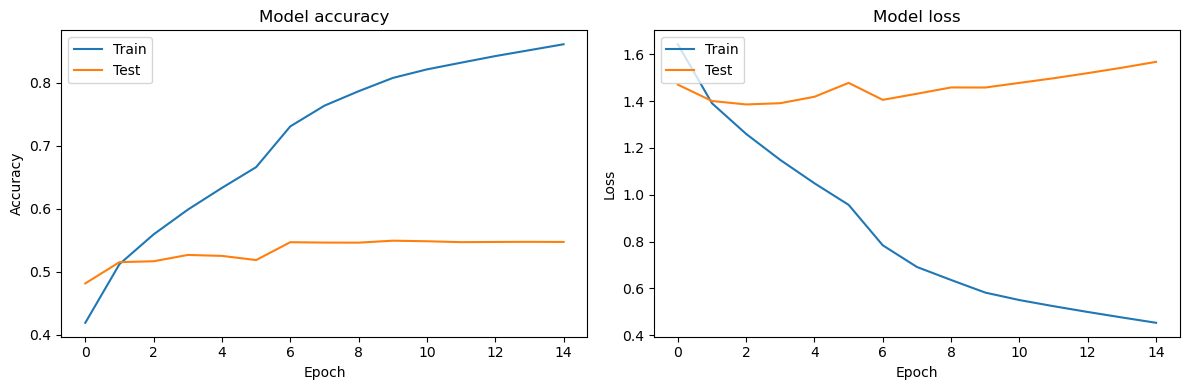

In [5]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

plt.tight_layout()
plt.show()

## #24 Regularization

In [ ]:
regularizer = tf.keras.regularizers.L2(0.005)
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal", kernel_regularizer=regularizer),
        tf.keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal", kernel_regularizer=regularizer),
        tf.keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal", kernel_regularizer=regularizer),
        tf.keras.layers.Dense(10, activation="softmax", kernel_regularizer=regularizer),
    ]
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.9, learning_rate=0.01, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", factor=0.2, patience=2, min_lr=0.001)
early_stopping = EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
callbacks = [early_stopping, reduce_lr]

# Train the model
history = model.fit(train_ds, epochs=20, validation_data=test_ds, batch_size=100, callbacks=callbacks)

Epoch 1/20
500/500 [==============================] - 9s 17ms/step - loss: 7.5125 - accuracy: 0.4196 - val_loss: 4.9783 - val_accuracy: 0.4753 - lr: 0.0100
Epoch 2/20
500/500 [==============================] - 8s 17ms/step - loss: 3.7600 - accuracy: 0.4852 - val_loss: 2.8759 - val_accuracy: 0.4964 - lr: 0.0100
Epoch 3/20
500/500 [==============================] - 8s 15ms/step - loss: 2.4261 - accuracy: 0.5046 - val_loss: 2.1176 - val_accuracy: 0.5087 - lr: 0.0100
Epoch 4/20
500/500 [==============================] - 8s 15ms/step - loss: 1.9365 - accuracy: 0.5159 - val_loss: 1.8413 - val_accuracy: 0.5149 - lr: 0.0100
Epoch 5/20
500/500 [==============================] - 9s 18ms/step - loss: 1.7528 - accuracy: 0.5235 - val_loss: 1.7425 - val_accuracy: 0.5196 - lr: 0.0100
Epoch 6/20
500/500 [==============================] - 10s 20ms/step - loss: 1.6827 - accuracy: 0.5286 - val_loss: 1.7082 - val_accuracy: 0.5227 - lr: 0.0100
Epoch 7/20
500/500 [==============================] - 9s 18ms/s

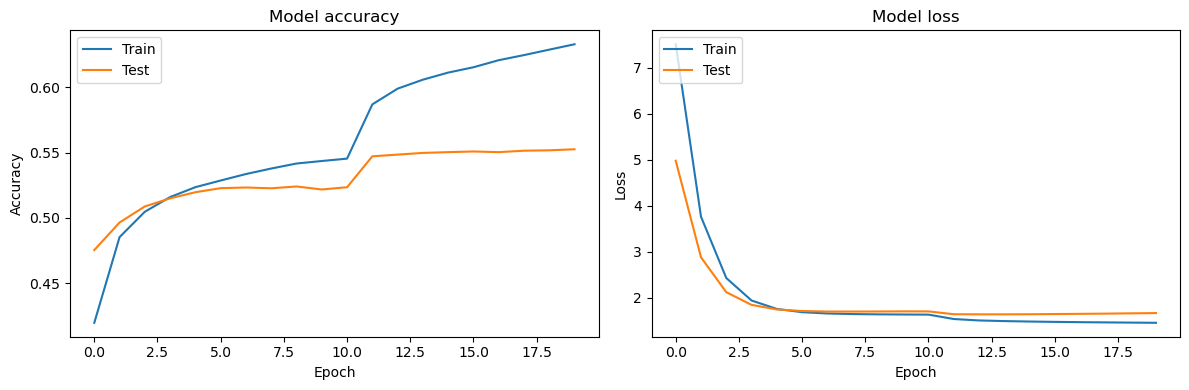

In [7]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

plt.tight_layout()
plt.show()

## #25 Dropout

In [5]:
model = tf.keras.models.Sequential(
    [
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dropout(0.5),  # Droput Layer
        tf.keras.layers.Dense(256, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dropout(0.5),  # Droput Layer
        tf.keras.layers.Dense(128, activation="relu", kernel_initializer="he_normal"),
        tf.keras.layers.Dropout(0.5),  # Droput Layer
        tf.keras.layers.Dense(10, activation="softmax"),
    ]
)

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.SGD(momentum=0.9, learning_rate=0.01, nesterov=True),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

reduce_lr = ReduceLROnPlateau(monitor="val_accuracy", factor=0.2, patience=2, min_lr=0.001)
early_stopping = EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
callbacks = [early_stopping, reduce_lr]

# Train the model
history = model.fit(train_ds, epochs=100, validation_data=test_ds, batch_size=100, callbacks=callbacks)

Epoch 1/100
258/258 [==============================] - 123s 226ms/step - loss: nan - accuracy: 0.0515 - val_loss: nan - val_accuracy: 0.0459 - lr: 0.0100
Epoch 2/100
258/258 [==============================] - 26s 82ms/step - loss: nan - accuracy: 0.0513 - val_loss: nan - val_accuracy: 0.0393 - lr: 0.0100
Epoch 3/100
258/258 [==============================] - 28s 81ms/step - loss: nan - accuracy: 0.0523 - val_loss: nan - val_accuracy: 0.0601 - lr: 0.0100
Epoch 4/100
258/258 [==============================] - 32s 101ms/step - loss: nan - accuracy: 0.0502 - val_loss: nan - val_accuracy: 0.0612 - lr: 0.0100
Epoch 5/100
258/258 [==============================] - 32s 97ms/step - loss: nan - accuracy: 0.0501 - val_loss: nan - val_accuracy: 0.0514 - lr: 0.0100
Epoch 6/100
258/258 [==============================] - 32s 88ms/step - loss: nan - accuracy: 0.0507 - val_loss: nan - val_accuracy: 0.0678 - lr: 0.0100
Epoch 7/100
258/258 [==============================] - 30s 89ms/step - loss: nan - ac

In [6]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten_1 (Flatten)         (None, 150528)            0         
                                                                 
 dense_4 (Dense)             (None, 512)               77070848  
                                                                 
 dropout_3 (Dropout)         (None, 512)               0         
                                                                 
 dense_5 (Dense)             (None, 256)               131328    
                                                                 
 dropout_4 (Dropout)         (None, 256)               0         
                                                                 
 dense_6 (Dense)             (None, 128)               32896     
                                                                 
 dropout_5 (Dropout)         (None, 128)              

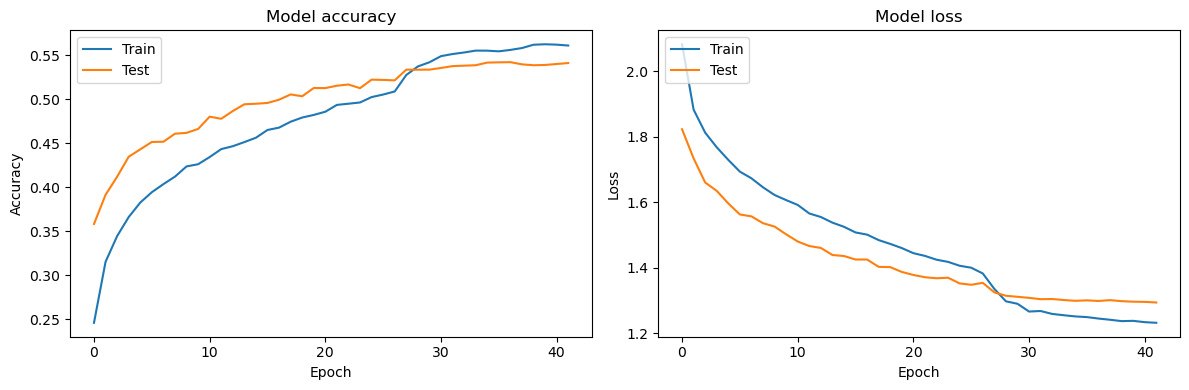

In [7]:
# Plot training & validation accuracy values
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')

plt.tight_layout()
plt.show()